# 2. Data Cleaning

Combine the three scraped tables into one dataset: **one row per player per season**, with their stats, their team's record, and their MVP vote share.

Issues found and fixed along the way:
1. **Name encoding:** some MVP names were saved with the wrong encoding (`Nikola JokiÄ` instead of `Nikola Jokić`), so they didn't match the player table.
2. **Traded players:** basketball-reference now labels a traded player's season total as `2TM`/`3TM` (older tutorials use `TOT`). Using `TOT` silently dropped ~1,900 player-seasons.
3. **"League Average" rows:** summary rows in the player table, not real players.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## MVP voting

In [2]:
mvps = pd.read_csv("mvps.csv")
mvps = mvps[["Player", "Year", "Pts Won", "Pts Max", "Share"]]


def fix_encoding(name):
    """Repair names that were decoded as Latin-1 instead of UTF-8 ("JokiÄ" -> "Jokić")."""
    try:
        return name.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return name    # already correct


mvps["Player"] = mvps["Player"].apply(fix_encoding)
mvps[mvps["Player"].str.contains("Joki|Don.i|Gin.bili|Stojakovi|Dragi")]["Player"].unique()

array(['Peja Stojaković', 'Manu Ginóbili', 'Goran Dragić', 'Nikola Jokić',
       'Luka Dončić'], dtype=object)

## Player stats

In [3]:
players = pd.read_csv("players.csv")
players = players.drop(columns=["Rk", "Awards"])    # "Awards" contains e.g. "MVP-1": the answer, never use it
players["Player"] = players["Player"].str.replace("*", "", regex=False)    # "*" marks Hall of Famers
players = players[players["Player"] != "League Average"]
players.head()

,Player,Age,Team,Pos,G,GS,MP,FG,FGA,FG%,...,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Year
0,Michael Jordan,27,CHI,SG,82,82,37.0,12.1,22.4,.539,...,1.4,4.6,6.0,5.5,2.7,1.0,2.5,2.8,31.5,1991
1,Karl Malone,27,UTA,PF,82,82,40.3,10.3,19.6,.527,...,2.9,8.9,11.8,3.3,1.1,1.0,3.0,3.3,29.0,1991
2,Bernard King,34,WSB,SF,64,64,37.5,11.1,23.6,.472,...,1.8,3.2,5.0,4.6,0.9,0.3,4.0,2.9,28.4,1991
3,Charles Barkley,27,PHI,SF,67,67,37.3,9.9,17.4,.570,...,3.9,6.3,10.1,4.2,1.6,0.5,3.1,2.6,27.6,1991
4,Patrick Ewing,28,NYK,C,81,81,38.3,10.4,20.3,.514,...,2.4,8.8,11.2,3.0,1.0,3.2,3.6,3.5,26.6,1991


### Traded players

A player traded mid-season has one row per team plus a season-total row (`2TM`, `3TM`, ...).
We keep only the total row and label it with the **last team** he played for.

In [4]:
players[players["Player"] == "James Harden"].query("Year == 2021")[["Player", "Year", "Team", "G", "PTS"]]

,Player,Year,Team,G,PTS
17514,James Harden,2021,2TM,44,24.6
17515,James Harden,2021,HOU,8,24.8
17516,James Harden,2021,BRK,36,24.6


In [5]:
group = players.groupby(["Player", "Year"])["Team"]
rows_per_player = group.transform("size")
last_team = group.transform("last")

is_single_team = rows_per_player == 1
is_season_total = players["Team"].str.endswith("TM")

players["Team"] = players["Team"].where(is_single_team, last_team)
players = players[is_single_team | is_season_total]

print("Duplicate player-seasons:", players.duplicated(["Player", "Year"]).sum())
players[players["Player"] == "James Harden"].query("Year == 2021")[["Player", "Year", "Team", "G", "PTS"]]

Duplicate player-seasons: 0


,Player,Year,Team,G,PTS
17514,James Harden,2021,BRK,44,24.6


## Combine players with MVP votes

In [6]:
combined = players.merge(mvps, on=["Player", "Year"], how="left")
combined[["Pts Won", "Pts Max", "Share"]] = combined[["Pts Won", "Pts Max", "Share"]].fillna(0)    # no votes = 0

unmatched = mvps.merge(players, on=["Player", "Year"], how="left", indicator=True).query("_merge == 'left_only'")
print("MVP vote-getters without player stats:", len(unmatched))

MVP vote-getters without player stats: 0


## Team standings

In [7]:
teams = pd.read_csv("teams.csv")
teams = teams[~teams["W"].str.contains("Division")]     # remove division header rows
teams["Team"] = teams["Team"].str.replace("*", "", regex=False)    # "*" marks playoff teams
teams["GB"] = teams["GB"].str.replace("—", "0")         # division leaders are 0 games back
teams.head()

,Team,W,L,W/L%,GB,PS/G,PA/G,SRS,Year
0,Boston Celtics,56,26,.683,0,111.5,105.7,5.22,1991
1,Philadelphia 76ers,44,38,.537,12.0,105.4,105.6,-0.39,1991
2,New York Knicks,39,43,.476,17.0,103.1,103.3,-0.43,1991
3,Washington Bullets,30,52,.366,26.0,101.4,106.4,-4.84,1991
4,New Jersey Nets,26,56,.317,30.0,102.9,107.5,-4.53,1991


Player stats use abbreviations (`ATL`), team standings use full names (`Atlanta Hawks`).
`nicknames.txt` maps one to the other.

In [8]:
nicknames = pd.read_csv("nicknames.txt").set_index("Abbreviation")["Name"].to_dict()
combined["Team"] = combined["Team"].map(nicknames)
print("Unmapped teams:", combined["Team"].isnull().sum())

Unmapped teams: 0


## Final dataset

In [9]:
stats = combined.merge(teams, on=["Team", "Year"], how="left")
print("Players without team stats:", stats["W"].isnull().sum())

text_columns = ["Player", "Team", "Pos"]
numeric_columns = [c for c in stats.columns if c not in text_columns]
stats[numeric_columns] = stats[numeric_columns].apply(pd.to_numeric)

stats.dtypes.value_counts()

Players without team stats: 0


float64    31
int64       6
object      3
Name: count, dtype: int64

The only missing values left are shooting percentages for players with **zero attempts** (0 ÷ 0).
They are kept as missing here and filled in the modeling notebook.

In [10]:
missing = stats.isnull().sum()
missing[missing > 0]

FG%       68
3P%     2162
2P%      118
eFG%      68
FT%      602
dtype: int64

In [11]:
stats.to_csv("player_mvp_stats.csv", index=False)
stats.shape

(16377, 40)

## Exploring the data

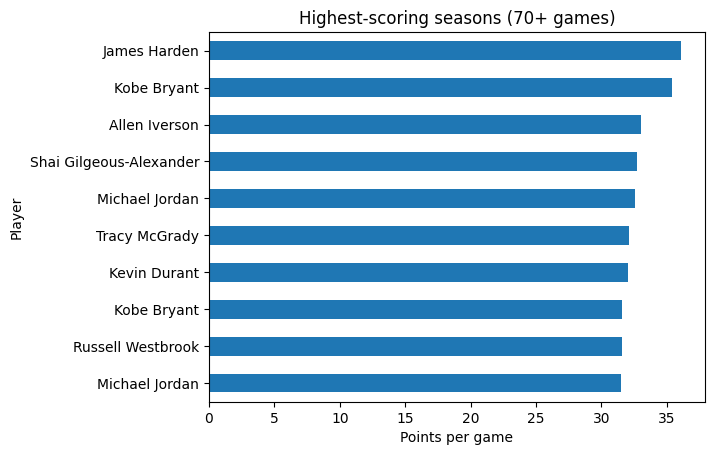

In [12]:
top_scorers = stats[stats["G"] > 70].sort_values("PTS", ascending=False).head(10)
top_scorers.plot.barh(x="Player", y="PTS", legend=False, title="Highest-scoring seasons (70+ games)")
plt.gca().invert_yaxis()
plt.xlabel("Points per game")
plt.show()

In [13]:
mvp_winners = stats.loc[stats.groupby("Year")["Share"].idxmax(), ["Year", "Player", "PTS", "W/L%", "Share"]]
mvp_winners.tail(10)

,Year,Player,PTS,W/L%,Share
10991,2016,Stephen Curry,30.1,0.890,1.000
11467,2017,Russell Westbrook,31.6,0.573,0.879
11953,2018,James Harden,30.4,0.793,0.955
12495,2019,Giannis Antetokounmpo,27.7,0.732,0.932
13027,2020,Giannis Antetokounmpo,29.5,0.767,0.952
13562,2021,Nikola Jokić,26.4,0.653,0.961
14101,2022,Nikola Jokić,27.1,0.585,0.875
14697,2023,Joel Embiid,33.1,0.659,0.915
15247,2024,Nikola Jokić,26.4,0.695,0.935
15808,2025,Shai Gilgeous-Alexander,32.7,0.829,0.913


Which stats move with MVP vote share? Points and team success matter most; defensive box-score stats much less.

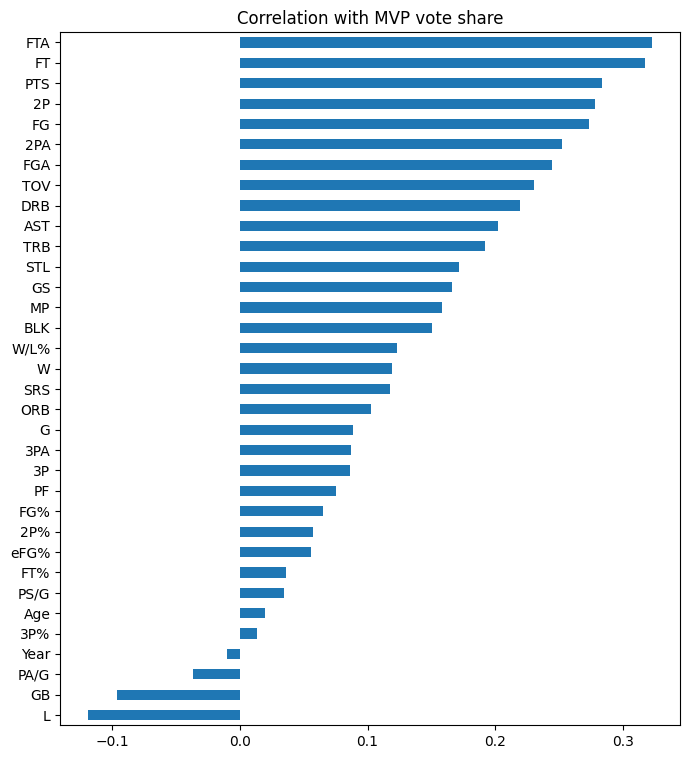

In [14]:
correlation = stats.corr(numeric_only=True)["Share"].drop(["Share", "Pts Won", "Pts Max"]).sort_values()
correlation.plot.barh(figsize=(8, 9), title="Correlation with MVP vote share")
plt.show()